In [66]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from synpop import io

In [3]:
bundle = io.load_bn_bundle(r'output\bn_bundle.pkl')

c:\Users\tang\miniconda3\envs\synpop\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [13]:
synpop = pd.read_csv(r'output\synpop_distribution.csv',index_col=0)
true = pd.read_csv(r"output\true_pop_ditribution.csv",index_col=0)
train = pd.read_csv(r'output\train_pop_ditribution.csv',index_col=0)
model = pd.read_csv(r"src\synpop\threshold\individual_distribution\model_distribution.csv",index_col=0)

In [12]:
bundle

{'h_model': <pgmpy.models.DiscreteBayesianNetwork.DiscreteBayesianNetwork at 0x15739685e50>,
 'p_model': <pgmpy.models.DiscreteBayesianNetwork.DiscreteBayesianNetwork at 0x1573b2ffdd0>,
 'config': ModelSchema(code_to_attr={'Head_age': {0: 3, 1: 4, 2: 5, 3: 6, 4: 7, 5: 8}, 'Head_gender': {0: 'female', 1: 'male'}, 'H_type': {0: 'couple', 1: 'couple_with_children', 2: 'couple_with_kid', 3: 'couple_with_minor', 4: 'only_adults', 5: 'only_adults_with_children', 6: 'only_adults_with_kid', 7: 'only_adults_with_minor', 8: 'single', 9: 'single_with_children', 10: 'single_with_kid', 11: 'single_with_minor'}, 'Member_rank': {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5}, 'age_cate': {0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8}, 'P_gender': {0: 'female', 1: 'male'}}, attr_to_code={'Head_age': {3: 0, 4: 1, 5: 2, 6: 3, 7: 4, 8: 5}, 'Head_gender': {'female': 0, 'male': 1}, 'H_type': {'couple': 0, 'couple_with_children': 1, 'couple_with_kid': 2, 'couple_with_minor': 3, 'only_adults': 4, 'only_adults_with_ch

In [32]:
dfs = [true,model,train]
attrs = ['P_gender', 'P_education', 'P_work', 'driver_license','prepaid_tickets', 'H_motor_v', 'H_venr_bike', 'age_cate']

NameError: name 'true' is not defined

In [9]:
def compare_distribution(dfs:list[pd.DataFrame],attrs:list[str],suffix:list) -> pd.DataFrame:
    """
    Helper function to compare the population type of population distributions among different
    dataframes.

    Args:
        dfs (list[pd.DataFrame]): _description_
        attrs (list[str]): _description_

    Returns:
        pd.DataFrame: _description_
    """
    for i, df in enumerate(dfs):
        dfs[i] = df.set_index(attrs)
    
    return pd.concat([df[df['prob']>0].add_suffix(f'_{suffix[i]}') for i, df in enumerate(dfs)], axis=1).fillna(0)
        

In [213]:
compare = compare_distribution(dfs,attrs,suffix=['true','model','train'])

In [214]:
compare.to_csv(r'output\type compare.csv')

In [242]:
def model_pruning_analysis(
    df,
    threshold_multiplier,
    N,
    columns: list = ['prob_model', 'prob_true', 'prob_train'],
    count_reference_pop_type=4409,
    plot=True,
    export_path=None,
):
    # Pre-calculate baseline metrics once (constant across threshold multipliers)
    sample_mask = df[columns[2]] > 0
    train_reference_ratio = sample_mask.sum() / count_reference_pop_type
    sample_reference_coverage = df[sample_mask][columns[1]].sum()

    records = []

    for t in threshold_multiplier:
        pruning = df[df[columns[0]] > (t / N)]

        bn_only_ratio = (
            (pruning[columns[1]] == 0).mean() if not pruning.empty else 0.0
        )
        bn_reference_ratio = (
            pruning[columns[1]] != 0
        ).sum() / count_reference_pop_type
        reference_coverage = pruning[columns[1]].sum()

        records.append({
            'threshold_multiplier': t,
            'BN_only_ratio': bn_only_ratio,
            'BN_reference_ratio': bn_reference_ratio,
            'reference_coverage': reference_coverage,
            'train_reference_ratio': train_reference_ratio,
            'sample_reference_coverage': sample_reference_coverage,
        })

    results_df = pd.DataFrame(records)

    if plot or export_path:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
        ax1.plot(
            results_df['threshold_multiplier'],
            results_df['BN_only_ratio'],
            color = 'blue',
            marker='o',
            linewidth=1.5,
            label='BN-only Ratio',
        )
        ax1.plot(
            results_df['threshold_multiplier'],
            results_df['BN_reference_ratio'],
            color = 'green',
            marker='o',
            linewidth=1.5,
            label='BN-reference Ratio',
        )
        # Baseline drawn as a horizontal dashed reference line
        ax1.axhline(
            y=train_reference_ratio,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label=f'Sample Reference Ratio Baseline ({train_reference_ratio:.3f})',
        )

        ax1.set_xlabel('Threshold Multiplier')
        ax1.set_ylabel('Proportion')
        ax1.set_title('Pruning Ratios vs. Sample Baseline')
        ax1.grid(True, linestyle='--', alpha=0.6)
        ax1.legend(loc='best')

        ax2.plot(
            results_df['threshold_multiplier'],
            results_df['reference_coverage'],
            marker='o',
            color='green',
            linewidth=1.5,
            label='Reference Population Coverage',
        )
        # Baseline drawn as a horizontal dashed reference line
        ax2.axhline(
            y=sample_reference_coverage,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label=f'Sample Reference Coverage Baseline ({sample_reference_coverage:.3f})',
        )

        ax2.set_xlabel('Threshold Multiplier')
        ax2.set_ylabel('Coverage Value')
        ax2.set_title('Population Coverage vs. Sample Baseline')
        ax2.grid(True, linestyle='--', alpha=0.6)
        ax2.legend(loc='best')

        plt.tight_layout()

        if export_path:
            plt.savefig(export_path, dpi=300)

        if plot:
            plt.show()
        else:
            plt.close(fig)

    return results_df

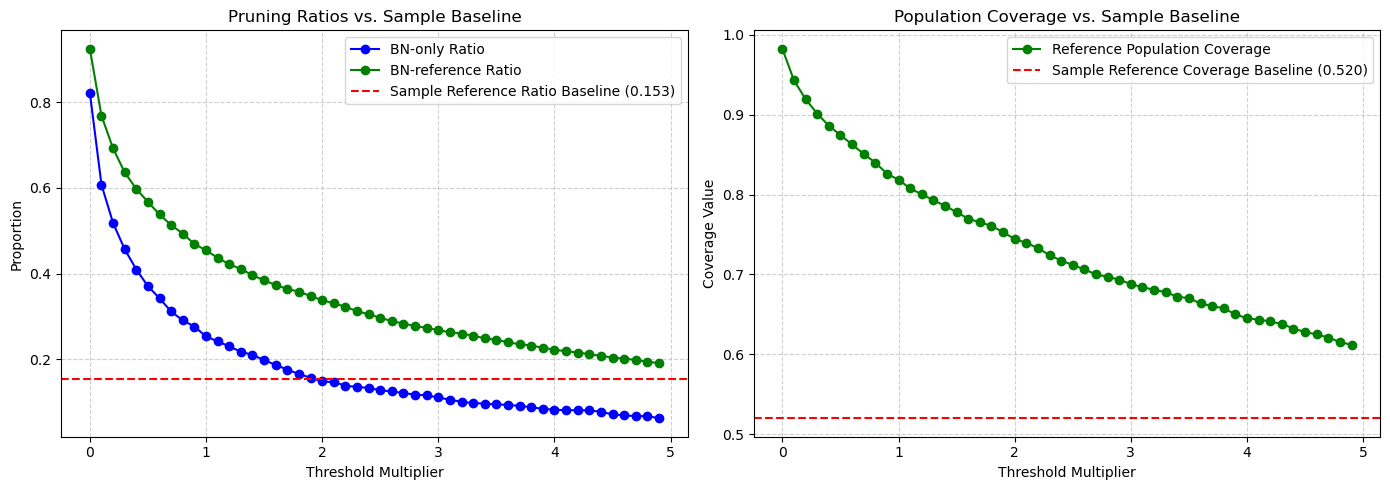

,threshold_multiplier,BN_only_ratio,BN_reference_ratio,reference_coverage,train_reference_ratio,sample_reference_coverage
0,0.0,0.821397,0.924246,0.982276,0.153096,0.520152
1,0.1,0.607147,0.767975,0.942789,0.153096,0.520152
2,0.2,0.517634,0.691767,0.919308,0.153096,0.520152
3,0.3,0.456589,0.635972,0.901207,0.153096,0.520152
4,0.4,0.409376,0.597188,0.886025,0.153096,0.520152
5,0.5,0.370436,0.567022,0.874308,0.153096,0.520152
6,0.6,0.342120,0.537764,0.862637,0.153096,0.520152
7,0.7,0.311416,0.513042,0.850738,0.153096,0.520152
8,0.8,0.290701,0.493082,0.840024,0.153096,0.520152
9,0.9,0.276261,0.468814,0.825983,0.153096,0.520152


In [243]:
model_pruning_analysis(
    df=compare,
    threshold_multiplier=np.arange(0,5,0.1),
    N=21938,
)

In [4]:
synpop

,P_gender,P_education,P_work,driver_license,prepaid_tickets,H_motor_v,H_venr_bike,age_cate,prob
0,0,Unfinished Elementary School,primary school pupil,0,0,1,3,0,0.008460
1,1,Unfinished Elementary School,primary school pupil,0,0,1,3,0,0.007177
2,1,secondary education: vocational certificate,non-working pensioner,1,0,1,0,6,0.006084
3,1,Unfinished Elementary School,primary school pupil,0,1,1,3,0,0.005941
4,1,secondary education: high school diploma,"employee, employer, self-employed or assisting",1,0,1,3,3,0.005846
...,...,...,...,...,...,...,...,...,...
4470,0,university,"household member, preschool child, other depen...",1,0,1,0,2,0.000048
4471,0,university,"household member, preschool child, other depen...",1,0,1,1,3,0.000048
4472,0,university,"household member, preschool child, other depen...",1,0,1,2,2,0.000048
4473,0,university,"household member, preschool child, other depen...",1,0,1,2,3,0.000048


# Calibration testing

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from synpop.calibration import calibrator
from synpop.config import AppConfig
from synpop.calibration.matrix import CalibrationInput
from synpop.calibration.matrix import CalibrationMatrixBuilder as matrix_builder
from synpop.calibration.calibrator import CALIBRATOR
from synpop import validation


ImportError: cannot import name 'maximum_threshold' from 'synpop.threshold.threshold' (C:\Users\tang\database\SynPop\synthetic_populations\src\synpop\threshold\threshold.py)

In [21]:
attrs = ['P_gender', 'P_education', 'P_work', 'driver_license','prepaid_tickets', 'H_motor_v', 'H_venr_bike', 'age_cate']

In [10]:
p_sample = pd.read_excel(r'input\P_sample_5%.xlsx')
h_sample = pd.read_excel(r'input\H_sample_5%.xlsx')


P_age
40-49    0.169159
60-69    0.166355
70+      0.149533
30-39    0.139252
18-29    0.119626
50-59    0.118692
6-14     0.107477
15-17    0.029907
Name: proportion, dtype: float64

In [46]:
pd.concat([model.groupby(by='P_work')['probability'].agg('sum'),p_sample.value_counts('P_work',normalize=True)],axis=1)

,probability,proportion
P_work,,
"employee, employer, self-employed or assisting",0.384581,0.471028
"household member, preschool child, other dependents",0.009475,0.012150
non-working pensioner,0.422844,0.261682
other unemployed,0.009987,0.014019
"person with own source of income, on parental leave",0.007263,0.011215
primary school pupil,0.072845,0.113084
secondary school student,0.020905,0.033645
unemployed seeking first job,0.004149,0.006542
university student,0.011072,0.021495


In [11]:
cfg = AppConfig.load(r"config\config.yaml")

In [24]:
calibration_input = CalibrationInput(
    h_df=h_sample,
    p_df=p_sample,
    h_marginals=cfg.calibration.h_marginals,
    p_marginals=cfg.calibration.p_marginals,
    h_attrs=cfg.calibration.h_attributes,
    p_attrs=cfg.calibration.p_attributes,
    h_id_col=cfg.train.h_id_col,
)
calibration_matrix = matrix_builder.build(
    calibration_input
)
calibrator = CALIBRATOR['hipf']
calibration_result = calibrator(calibration_matrix).fit(
    max_iter=cfg.calibration.max_iterations,
    tolerance=cfg.calibration.tolerance,
    **cfg.calibration.kwargs,
)

INFO:synpop.calibration.calibrator:HIPF Converged after 608 iterations. Final relative absolute error is: 0.000000


In [11]:
p_bn_t05 = pd.read_csv(r'output\p_bn_t05_4.csv')
h_bn_t05 = pd.read_csv(r'output\h_bn_t05_4.csv')
p_bn_t05['P_age'] = p_bn_t05['age_cate']

In [9]:
p_sample ['P_age'].value_counts(normalize=True)

P_age
40-49    0.169159
60-69    0.166355
70+      0.149533
30-39    0.139252
18-29    0.119626
50-59    0.118692
6-14     0.107477
15-17    0.029907
Name: proportion, dtype: float64

In [26]:
p_marginals_bn= {
    "P_age": {
    "0": 2549, 
    "1": 790,  # 6–17
    "2": 2736,       # 18–29
    "3": 3270,       # 30–39
    "4": 3702,       # 40–49
    "5": 2813,       # 50–59
    "6": 3139,       # 60–69
    "7": 2939,       # 70+ in the training data
}, 
    "P_gender": {"1": 10553, "0": 11385}, 
    "P_education": {
    "higher vocational": 519, 
    "primary school": 2290, 
    "secondary education: high school diploma": 7071, 
    "secondary education: vocational certificate": 6470, 
    "Unfinished Elementary School": 2785,
    "university":2803
    }, 
    "P_work": {
    "employee, employer, self-employed or assisting": 10616,
    "household member, preschool child, other dependents": 260,
    "non-working pensioner": 5216,
    "other unemployed": 358,
    "person with own source of income, on parental leave": 226,
    "primary school pupil": 2639,
    "secondary school student": 859,
    "unemployed seeking first job": 91,
    "university student": 383,
    "woman on maternity leave": 583,
    "working pensioner": 493,
    "working secondary school student or apprentice": 89,
    "working university student": 125
    },
    "driver_license": {"1": 13303, "0": 8635},
    "prepaid_tickets": {"0": 14752, "1": 7186}
    }
h_marginals = {
    "H_motor_v": {"0":2593,"1": 4505, "2": 1560, "3": 603}, 
    "H_venr_bike": {"0": 4289, "1": 1576, "2": 1667, "3": 1729}
    }
p_attributes_bn = [
    "P_gender",
    "P_age",
    "P_education",
    "P_work",
    "driver_license",
    "prepaid_tickets",
    ]
h_attributes = ["H_motor_v", "H_venr_bike"]

In [27]:
calibration_input_bn_1 = CalibrationInput(
    h_df=h_bn_t05,
    p_df=p_bn_t05,
    h_marginals=h_marginals,
    p_marginals=p_marginals_bn,
    h_attrs=h_attributes,
    p_attrs=p_attributes_bn,
    h_id_col=cfg.train.h_id_col,
)
calibration_matrix_bn = matrix_builder.build(
    calibration_input_bn_1
)


In [28]:
calibration_matrix_bn.X.shape

(9208, 41)

In [30]:
def augment(h_bn,p_bn,h_id):        
    h_bn["weight"] = (
        calibration_result.weights
    ) 
    p_bn["weight"] = p_bn[h_id].map(h_bn.set_index(h_id)["weight"])
    return h_bn,p_bn

In [97]:
validation.compute_metrics(
    'sample',
    calibration_result.weights @ calibration_matrix.x_h,
    calibration_matrix.h_m_ar,
    calibration_result.weights @ calibration_matrix.x_p,
    calibration_matrix.p_m_ar,
    'h_sample',
    'p_sample',
    is_converged=True
    )

{'sample': {'filename_h': 'h_sample',
  'filename_p': 'p_sample',
  'h_rmse': np.float64(2.4770673574486296e-05),
  'p_rmse': np.float64(0.0007441439760734583),
  'h_zscore': np.float64(2.0505510282214345e-12),
  'p_zscore': np.float64(5.519491232201439e-09),
  'is_converged': True}}

In [25]:
validation.compute_metrics(
    'bn',
    calibration_bn.weights @ calibration_matrix_bn.x_h,
    calibration_matrix_bn.h_m_ar,
    calibration_bn.weights @ calibration_matrix_bn.x_p,
    calibration_matrix_bn.p_m_ar,
    'h_bn',
    'p_bn',
    is_converged=True
    )

{'bn': {'filename_h': 'h_bn',
  'filename_p': 'p_bn',
  'h_rmse': np.float64(6.899563272398729e-06),
  'p_rmse': np.float64(0.0007194186558575137),
  'h_zscore': np.float64(2.57913361792954e-13),
  'p_zscore': np.float64(5.079549925175344e-09),
  'is_converged': True}}

In [10]:
validation.compute_metrics(
    'bn',
    calibration_bn.weights @ calibration_matrix_bn.x_h,
    calibration_matrix_bn.h_m_ar,
    calibration_bn.weights @ calibration_matrix_bn.x_p,
    calibration_matrix_bn.p_m_ar,
    'h_bn',
    'p_bn',
    is_converged=True
    )

{'bn': {'filename_h': 'h_bn',
  'filename_p': 'p_bn',
  'h_rmse': np.float64(0.008580691394861534),
  'p_rmse': np.float64(6.3367274273533925),
  'h_zscore': np.float64(2.523389354337847e-07),
  'p_zscore': np.float64(4.129970659956404),
  'is_converged': True}}

In [16]:
import pandas as pd
import io
from contextlib import closing
import sqlite3


with closing(sqlite3.connect(r'output\experiments.db')) as conn:
    blobs = conn.execute(
        """
        SELECT household, individual
        FROM Bayesian_runs
        WHERE threshold = ?
        """,
        (0.5,),
    ).fetchone()

h_loaded = pd.read_parquet(io.BytesIO(blobs[0]))
p_loaded = pd.read_parquet(io.BytesIO(blobs[1]))

In [31]:
p_loaded['P_education'].value_counts(normalize=True)

P_education
secondary education: vocational certificate    0.328612
secondary education: high school diploma       0.323070
Unfinished Elementary School                   0.111085
primary school                                 0.109806
university                                     0.108764
higher vocational                              0.018664
Name: proportion, dtype: float64

In [43]:
p_sample['P_work'].value_counts(normalize=True)

P_work
employee, employer, self-employed or assisting         0.471028
non-working pensioner                                  0.261682
primary school pupil                                   0.113084
secondary school student                               0.033645
working pensioner                                      0.026168
woman on maternity leave                               0.024299
university student                                     0.021495
other unemployed                                       0.014019
household member, preschool child, other dependents    0.012150
person with own source of income, on parental leave    0.011215
unemployed seeking first job                           0.006542
working secondary school student or apprentice         0.002804
working university student                             0.001869
Name: proportion, dtype: float64

In [74]:
def maximum_threshold(df:pd.DataFrame) -> float:
    """
    Calculate the maximum threshold for model pruning.

    Args:
        df (pd.DataFrame): The dataframe of population distribution derived from two-layer
        Bayesian model.
    """
    minimum_prob = 1
    columns = df.columns.to_list()
    columns.remove('probability')
    for col in columns:
        max_prob_per_category = df.groupby([col])['probability'].max()
        prob = max_prob_per_category.min()
        if prob<minimum_prob:
            minimum_prob = prob
    return minimum_prob


In [80]:
maximum_threshold(model)*21938

0.736266945473341